# 04 — Análisis de errores, interpretabilidad y sesgos
## Proyecto final de Machine Learning — Grupo 11 · Lending Club

**Objetivo:** entender *dónde* y *por qué* falla el modelo elegido, qué variables usa y si trata distinto a ciertos grupos.

**Regla importante:** este análisis se hace sobre **validación (2015)**, no sobre test. Lo que encontremos aquí puede usarse para mejorar el modelo
sin contaminar la evaluación final. Una sección opcional al final (apagada por defecto) describe el comportamiento en test, **solo después** de haber
corrido la etapa `final`, y sus hallazgos no deben usarse para modificar el modelo.

**Requisitos:** haber ejecutado el notebook 02 (o `--stage prepare`) y el 03 (o `--stage tune` + `--stage compare`), que dejan `data/processed/*.parquet` y `outputs/best_params.json`.


In [8]:
import os
import sys
import json
import warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.inspection import PartialDependenceDisplay, permutation_importance

from src import config, data, evaluate, features, models

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
SEED = config.SEED
np.random.seed(SEED)

QUICK = os.environ.get("QUICK_RUN") == "1"     # depuración rápida
MIN_PRECISION = 0.40
MIN_ROWS_SEGMENT = 500                         # grupos con menos filas no se reportan (métricas poco confiables)
ANALYZE_TEST = False                           # poner True SOLO después de ejecutar la etapa final (ver sección 9)
ANALYZE_TEST = ANALYZE_TEST or os.environ.get("ANALYZE_TEST") == "1"

config.OUTPUTS.mkdir(parents=True, exist_ok=True)
config.FIGURES.mkdir(parents=True, exist_ok=True)


def savefig(name):
    plt.savefig(config.FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")


## 1. Modelo y predicciones en validación

In [9]:
params_file = config.OUTPUTS / "best_params.json"
if not params_file.exists():
    raise FileNotFoundError("Falta outputs/best_params.json. Ejecuta el notebook 03 o: python -m src.train --stage compare")
payload = json.loads(params_file.read_text(encoding="utf-8"))
if "primary_model" not in payload:
    raise KeyError("best_params.json no tiene 'primary_model'. Completa el notebook 03 (sección 7) o ejecuta --stage compare")

primary = payload["primary_model"]
grey = bool(payload.get("include_grey_zone", False))
params = payload["best_params"][primary]
print(f"Modelo principal: {primary} | zona gris: {grey}\nHiperparámetros: {params}")

train, valid = data.load_splits(("train", "valid"))

artifact = config.DATA_PROCESSED / "artifacts" / "model_final.joblib"
if artifact.exists():
    model = joblib.load(artifact)
    print("Modelo cargado desde", artifact)
else:
    print("No hay modelo guardado (la etapa final aún no se ha ejecutado): se reentrena con train, igual que haría esa etapa.")
    X_tr, y_tr = models.get_xy(train, grey)
    model = models.fit_pipeline(primary, params, X_tr, y_tr, grey)

X_va, y_va = models.get_xy(valid, grey)
valid = valid.copy()
valid["score"] = model.predict_proba(X_va)[:, 1]

thr, rule = evaluate.choose_threshold(y_va, valid["score"].values, MIN_PRECISION)
valid["pred_malo"] = (valid["score"] >= thr).astype(int)
print(f"\nUmbral operativo: {thr:.4f}  ({rule})")
print(f"Validación: {len(valid):,} préstamos | tasa de default: {y_va.mean():.3f}")


Modelo principal: Gradient boosting | zona gris: False
Hiperparámetros: {'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 150, 'learning_rate': 0.03, 'l2_regularization': 0.0}
No hay modelo guardado (la etapa final aún no se ha ejecutado): se reentrena con train, igual que haría esa etapa.

Umbral operativo: 0.2346  (mayor recall con precisión >= 40% en validación)
Validación: 375,546 préstamos | tasa de default: 0.202


## 2. Rendimiento global en validación

In [10]:
glob = evaluate.evaluate_scores(y_va, valid["score"].values, MIN_PRECISION)
umbral = evaluate.metrics_at_threshold(y_va, valid["score"].values, thr)
pd.concat([pd.Series(glob, name="ranking (independiente del umbral)"),
           pd.Series(umbral, name="a umbral fijo")], axis=1).round(4)


,ranking (independiente del umbral),a umbral fijo
pr_auc,0.3941,NaN
roc_auc,0.7152,NaN
ks,0.3102,NaN
recall@p40,0.4418,NaN
umbral@p40,0.2346,NaN
lift_top10,2.4287,NaN
brier,0.1466,NaN
tasa_default,0.2019,NaN
umbral,NaN,0.2346
precision,NaN,0.4000


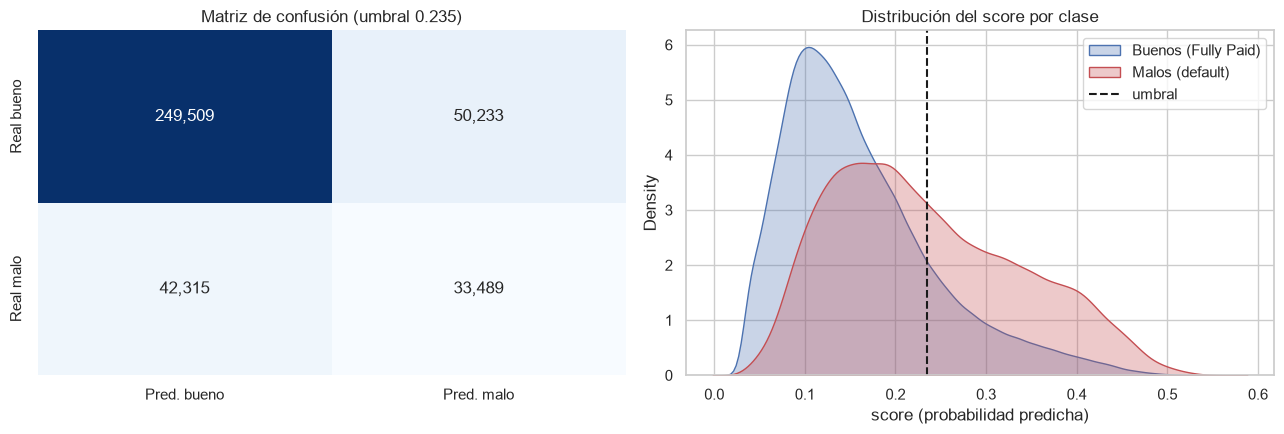

In [11]:
cm = np.array([[umbral["tn"], umbral["fp"]], [umbral["fn"], umbral["tp"]]])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Pred. bueno", "Pred. malo"], yticklabels=["Real bueno", "Real malo"])
axes[0].set_title(f"Matriz de confusión (umbral {thr:.3f})")
for clase, color, etiqueta in ((0, "#4C72B0", "Buenos (Fully Paid)"), (1, "#C44E52", "Malos (default)")):
    sns.kdeplot(valid.loc[valid["target"] == clase, "score"], ax=axes[1], color=color, fill=True, alpha=0.3, label=etiqueta, warn_singular=False)
axes[1].axvline(thr, color="k", ls="--", label="umbral")
axes[1].set_title("Distribución del score por clase")
axes[1].set_xlabel("score (probabilidad predicha)")
axes[1].legend()
plt.tight_layout()
savefig("04_global")
plt.show()


**Lectura:** (completar) ¿cuántos defaults se escapan (falsos negativos) y cuántos buenos pagadores se marcan por error (falsos positivos)?
Cuanto más se solapan las dos distribuciones, menos separable es el problema con la información disponible en la solicitud.


## 3. Ranking y calibración por deciles de score

Se ordenan los préstamos por score y se divide en 10 grupos iguales. Un buen modelo muestra una tasa real de default que crece de forma monótona con el decil;
el *lift* del decil superior dice cuántas veces más defaults hay ahí que en promedio.


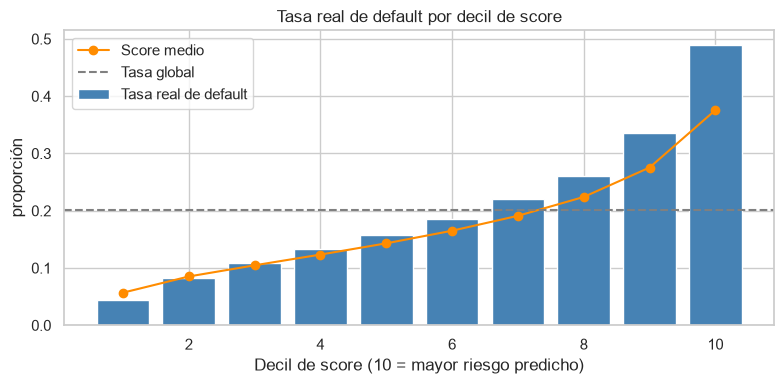

,n,tasa_default_real,score_medio,lift
decil,,,,
1,37555,0.0439,0.0569,0.2175
2,37555,0.0827,0.0852,0.4097
3,37554,0.1086,0.1047,0.5378
4,37555,0.1333,0.1235,0.6604
5,37554,0.1575,0.1431,0.7803
6,37555,0.1860,0.1651,0.9217
7,37554,0.2203,0.1911,1.0915
8,37555,0.2600,0.2241,1.2882
9,37554,0.3359,0.2755,1.6641


In [12]:
valid["decil"] = pd.qcut(valid["score"].rank(method="first"), 10, labels=False) + 1
deciles = valid.groupby("decil").agg(
    n=("target", "size"), tasa_default_real=("target", "mean"), score_medio=("score", "mean")
)
deciles["lift"] = deciles["tasa_default_real"] / y_va.mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(deciles.index, deciles["tasa_default_real"], color="steelblue", label="Tasa real de default")
ax.plot(deciles.index, deciles["score_medio"], color="darkorange", marker="o", label="Score medio")
ax.axhline(y_va.mean(), color="gray", ls="--", label="Tasa global")
ax.set_xlabel("Decil de score (10 = mayor riesgo predicho)"); ax.set_ylabel("proporción")
ax.set_title("Tasa real de default por decil de score"); ax.legend()
plt.tight_layout(); savefig("04_deciles"); plt.show()
deciles.round(4)


**Lectura:** (completar) ¿la tasa real sube monótonamente? ¿el score medio se parece a la tasa real o está inflado (efecto de `class_weight`)? ¿cuál es el lift del decil 10?


## 4. Errores por segmentos

Se calculan las métricas por subgrupos de la población. Un buen promedio global puede esconder grupos donde el modelo funciona mucho peor.
Columnas clave: `recall` (defaults detectados), `fpr` (buenos pagadores marcados por error), `roc_auc` (capacidad de ordenar dentro del grupo).
Los cuantiles (`fico_bin`, `dti_bin`, ...) se calculan sobre validación.


In [13]:
valid = evaluate.add_analysis_segments(valid)

SEGMENTOS = ["fico_bin", "dti_bin", "income_bin", "loan_bin", "term_months", "purpose",
             "home_ownership", "emp_bin", "verification_status", "state_group"]
seg = pd.concat([evaluate.segment_metrics(valid, col, thr, min_rows=MIN_ROWS_SEGMENT) for col in SEGMENTOS], ignore_index=True)
seg.to_csv(config.OUTPUTS / "error_analysis_segments_valid.csv", index=False)
seg.round(3)


,segmento,valor,n,tasa_default,score_medio,pct_marcados,recall,fpr,precision,roc_auc,pr_auc
0,fico_bin,1) 662–672,108696,0.255,0.216,0.329,0.527,0.260,0.410,0.684,0.435
1,fico_bin,2) 672–682,60833,0.235,0.202,0.285,0.487,0.222,0.403,0.691,0.412
2,fico_bin,3) 682–697,72059,0.207,0.180,0.226,0.431,0.173,0.394,0.693,0.381
3,fico_bin,4) 697–717,66781,0.170,0.148,0.151,0.343,0.112,0.386,0.704,0.338
4,fico_bin,5) 717–848,67177,0.111,0.103,0.064,0.211,0.046,0.367,0.738,0.276
5,dti_bin,1) -0.0–11.1,75180,0.146,0.134,0.099,0.254,0.073,0.372,0.707,0.297
6,dti_bin,2) 11.1–16.0,75158,0.169,0.150,0.145,0.328,0.108,0.382,0.709,0.339
7,dti_bin,3) 16.0–20.8,75114,0.193,0.170,0.203,0.402,0.155,0.383,0.705,0.368
8,dti_bin,4) 20.8–26.8,75004,0.224,0.193,0.274,0.483,0.214,0.394,0.697,0.400
9,dti_bin,5) 26.8–90.0,75080,0.278,0.225,0.393,0.604,0.312,0.427,0.700,0.471


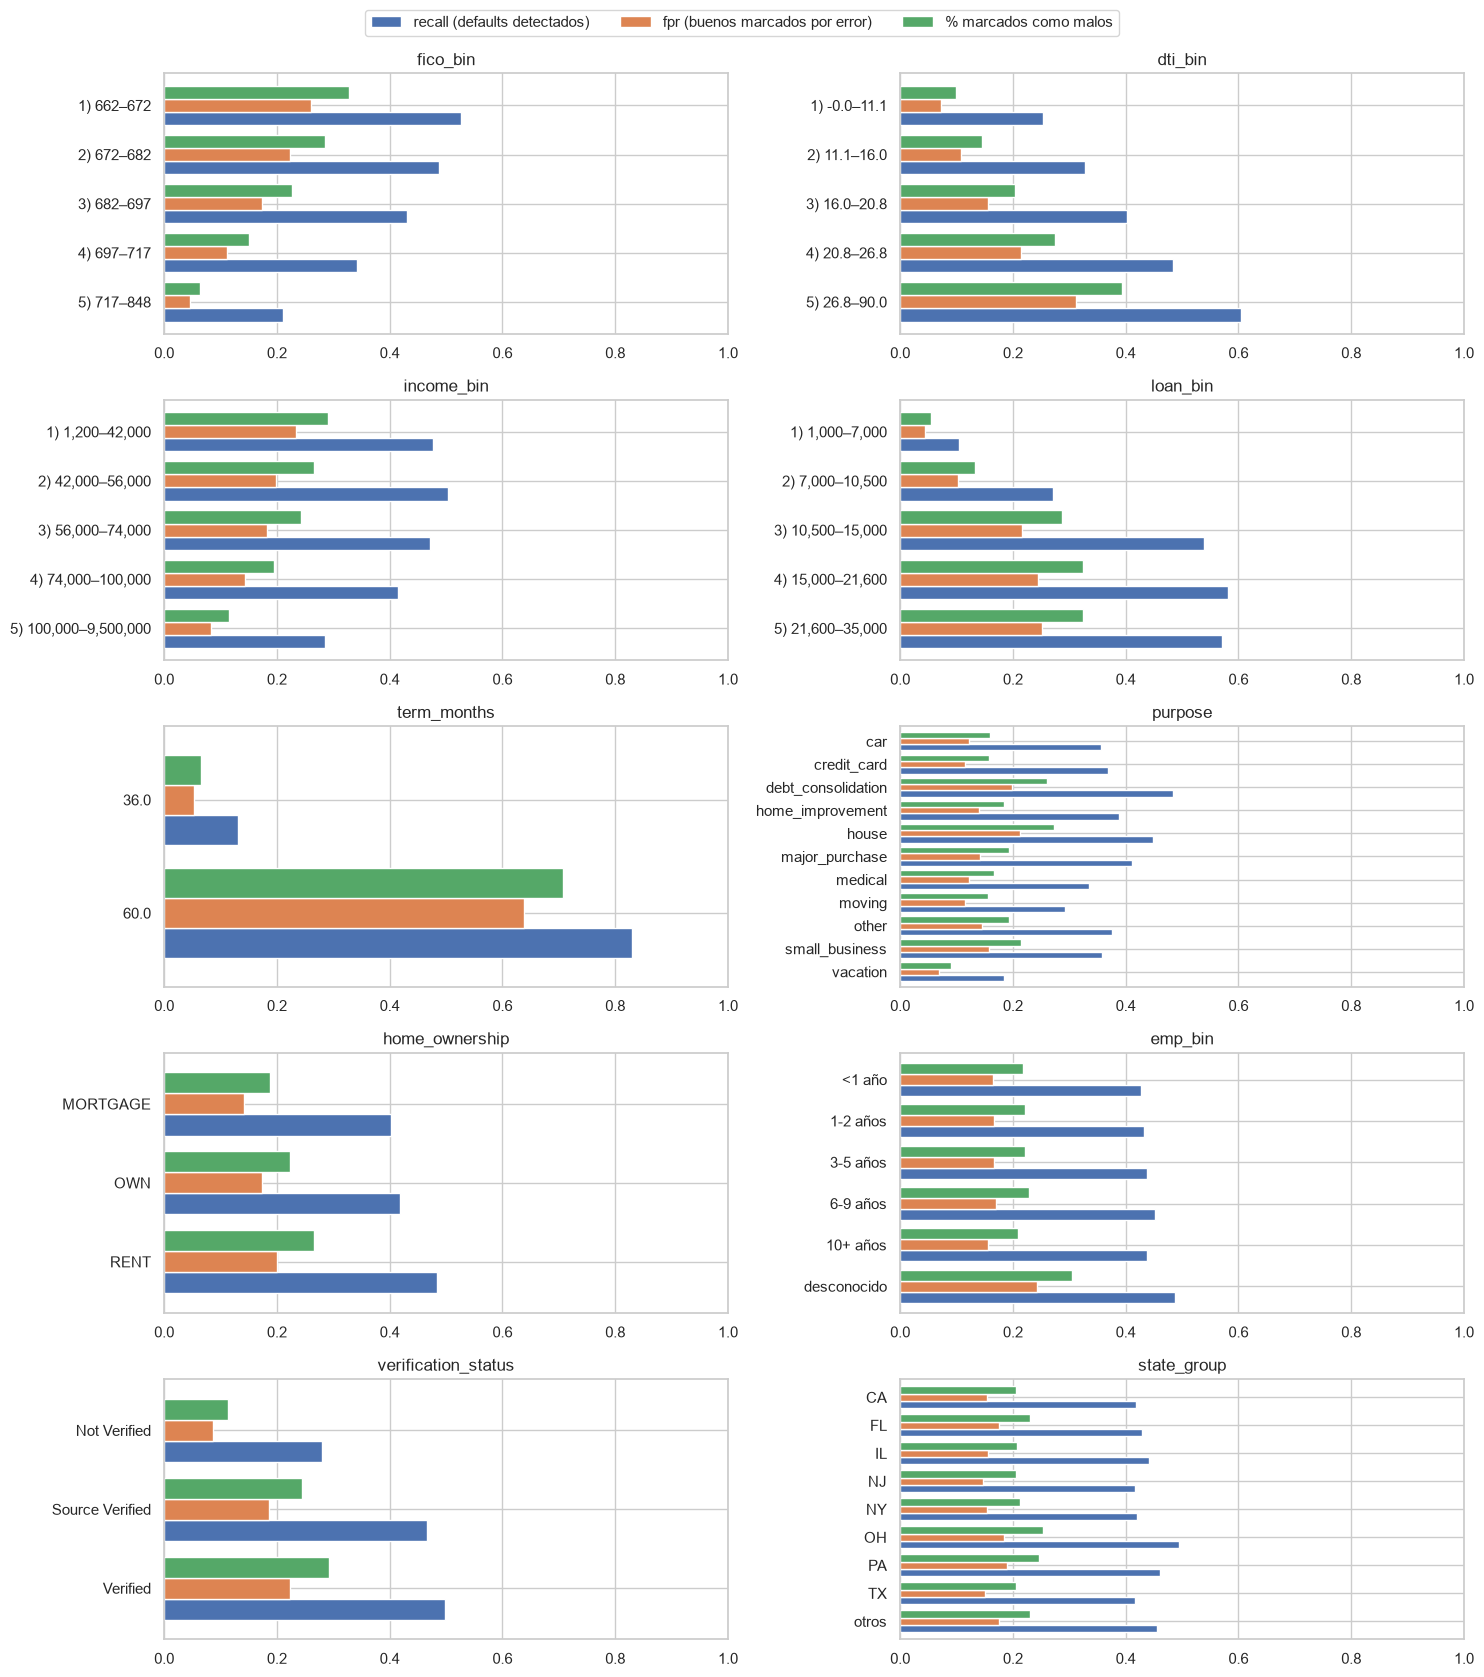

In [14]:
n_seg = len(SEGMENTOS)
fig, axes = plt.subplots((n_seg + 1) // 2, 2, figsize=(15, 3.3 * ((n_seg + 1) // 2)))
for ax, col in zip(axes.ravel(), SEGMENTOS):
    t = seg[seg["segmento"] == col].set_index("valor")[["recall", "fpr", "pct_marcados"]].iloc[::-1]
    t.plot(kind="barh", ax=ax, width=0.8, legend=False)
    ax.set_title(col); ax.set_ylabel(""); ax.set_xlim(0, 1)
for ax in axes.ravel()[n_seg:]:
    ax.axis("off")
handles, labels = axes.ravel()[0].get_legend_handles_labels()
fig.legend(handles, ["recall (defaults detectados)", "fpr (buenos marcados por error)", "% marcados como malos"],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(); savefig("04_segmentos"); plt.show()


In [15]:
# Segmentos donde el modelo ordena peor (menor ROC-AUC) o se escapan más defaults (menor recall)
print("Menor ROC-AUC:")
display(seg.sort_values("roc_auc").head(6)[["segmento", "valor", "n", "tasa_default", "roc_auc", "recall", "fpr"]].round(3))
print("Menor recall:")
display(seg.sort_values("recall").head(6)[["segmento", "valor", "n", "tasa_default", "roc_auc", "recall", "fpr"]].round(3))


Menor ROC-AUC:


,segmento,valor,n,tasa_default,roc_auc,recall,fpr
32,purpose,vacation,2191,0.181,0.635,0.184,0.069
15,loan_bin,"1) 1,000–7,000",77892,0.152,0.644,0.104,0.045
21,term_months,60.0,92520,0.364,0.657,0.830,0.638
20,term_months,36.0,283026,0.149,0.663,0.132,0.053
26,purpose,house,1331,0.251,0.667,0.449,0.213
31,purpose,small_business,3081,0.283,0.670,0.359,0.157


Menor recall:


,segmento,valor,n,tasa_default,roc_auc,recall,fpr
15,loan_bin,"1) 1,000–7,000",77892,0.152,0.644,0.104,0.045
20,term_months,36.0,283026,0.149,0.663,0.132,0.053
32,purpose,vacation,2191,0.181,0.635,0.184,0.069
4,fico_bin,5) 717–848,67177,0.111,0.738,0.211,0.046
5,dti_bin,1) -0.0–11.1,75180,0.146,0.707,0.254,0.073
16,loan_bin,"2) 7,000–10,500",73018,0.176,0.680,0.272,0.102


**Lectura:** (completar) ¿en qué segmentos empeora el modelo y por qué podría ser (menos datos, menor señal, otro régimen de riesgo)?
Distinguir entre diferencias de `recall`/`fpr` (cómo se aplica el umbral) y de `roc_auc` (qué tan bien ordena el modelo en ese grupo).


## 5. Casos problemáticos

- **Falsos negativos:** defaults que el modelo dejó pasar con score bajo (los más costosos para un prestamista).
- **Falsos positivos:** buenos pagadores con score muy alto (los más injustos para el solicitante).

La tabla de abajo compara a los defaults **detectados** (TP) con los **no detectados** (FN) usando la diferencia estandarizada de medias:
las variables con mayor diferencia son las que distinguen a los defaults que el modelo no ve.


In [16]:
cols_caso = ["id", "issue_date", "loan_amnt", "term_months", "annual_inc", "dti", "fico_avg",
             "purpose", "home_ownership", "emp_length_years", "score"]
fn = valid[(valid["target"] == 1) & (valid["pred_malo"] == 0)].sort_values("score").head(10)
fp = valid[(valid["target"] == 0) & (valid["pred_malo"] == 1)].sort_values("score", ascending=False).head(10)
print("10 defaults con el score MÁS BAJO (falsos negativos más claros):")
display(fn[cols_caso].round(3))
print("10 buenos pagadores con el score MÁS ALTO (falsos positivos más claros):")
display(fp[cols_caso].round(3))


10 defaults con el score MÁS BAJO (falsos negativos más claros):


,id,issue_date,loan_amnt,term_months,annual_inc,dti,fico_avg,purpose,home_ownership,emp_length_years,score
51142,64959035,2015-11-01,25000.0,36.0,180000.0,8.43,777.0,debt_consolidation,MORTGAGE,1.0,0.031
186781,55422237,2015-07-01,5000.0,36.0,82450.0,0.64,822.0,home_improvement,MORTGAGE,10.0,0.031
93884,61310319,2015-10-01,25000.0,36.0,150000.0,15.74,772.0,debt_consolidation,MORTGAGE,2.0,0.032
295969,44016868,2015-04-01,16000.0,36.0,300000.0,6.93,822.0,credit_card,MORTGAGE,5.0,0.032
15923,67406916,2015-12-01,10000.0,36.0,98800.0,3.40,832.0,credit_card,MORTGAGE,10.0,0.032
361566,38549236,2015-01-01,9900.0,36.0,142000.0,13.04,792.0,debt_consolidation,MORTGAGE,9.0,0.032
182890,55847350,2015-07-01,25000.0,36.0,107000.0,15.00,792.0,debt_consolidation,MORTGAGE,10.0,0.032
125351,60246818,2015-09-01,10250.0,36.0,96312.0,15.20,787.0,home_improvement,MORTGAGE,10.0,0.033
63469,63919895,2015-11-01,15000.0,36.0,95000.0,2.44,807.0,home_improvement,MORTGAGE,10.0,0.034
188733,55380368,2015-07-01,15000.0,36.0,125000.0,16.02,787.0,home_improvement,MORTGAGE,10.0,0.034


10 buenos pagadores con el score MÁS ALTO (falsos positivos más claros):


,id,issue_date,loan_amnt,term_months,annual_inc,dti,fico_avg,purpose,home_ownership,emp_length_years,score
14862,67367678,2015-12-01,12800.0,60.0,32000.0,38.82,682.0,debt_consolidation,RENT,10.0,0.541
189684,55169665,2015-07-01,17225.0,60.0,45000.0,37.76,677.0,debt_consolidation,RENT,0.0,0.540
318026,40960541,2015-03-01,15475.0,60.0,50000.0,38.19,667.0,debt_consolidation,RENT,7.0,0.539
91659,61873305,2015-10-01,35000.0,60.0,61140.0,45.77,667.0,debt_consolidation,RENT,10.0,0.538
282086,46244555,2015-04-01,10625.0,60.0,25400.0,39.41,672.0,debt_consolidation,RENT,0.0,0.537
286190,45444458,2015-04-01,10000.0,60.0,29000.0,39.42,662.0,medical,RENT,1.0,0.535
92405,62032392,2015-10-01,22000.0,60.0,57000.0,38.36,682.0,debt_consolidation,RENT,8.0,0.535
183426,55463000,2015-07-01,12000.0,60.0,24000.0,38.00,672.0,debt_consolidation,RENT,10.0,0.534
321266,41207515,2015-02-01,14725.0,60.0,41500.0,38.98,682.0,debt_consolidation,RENT,0.0,0.533
223738,51956475,2015-06-01,15000.0,60.0,40000.0,35.85,667.0,debt_consolidation,RENT,10.0,0.532


In [17]:
num_cols = [c for c in config.NUM_FEATURES if c in valid.columns]
tp_df = valid[(valid["target"] == 1) & (valid["pred_malo"] == 1)]
fn_df = valid[(valid["target"] == 1) & (valid["pred_malo"] == 0)]
dif = ((fn_df[num_cols].mean() - tp_df[num_cols].mean()) / valid[num_cols].std()).rename("dif. estandarizada (FN − TP)")
comp = pd.concat([tp_df[num_cols].mean().rename("media TP"), fn_df[num_cols].mean().rename("media FN"), dif], axis=1)
comp.reindex(dif.abs().sort_values(ascending=False).index).round(3)


,media TP,media FN,dif. estandarizada (FN − TP)
term_months,56.026,39.249,-1.622
loan_to_income,0.311,0.202,-0.965
loan_amnt,18298.594,13690.906,-0.541
dti,23.510,18.941,-0.528
fico_avg,682.079,692.010,0.327
inq_last_6mths,0.843,0.655,-0.214
annual_inc,63163.906,76189.126,0.174
revol_util,57.970,53.890,-0.171
mort_acc,1.224,1.547,0.163
open_acc,12.791,11.934,-0.153


**Lectura:** (completar) ¿qué perfil tienen los defaults que el modelo no detecta? Si se parecen a los buenos pagadores en todas las variables disponibles,
es una limitación de información (no de modelo): la solicitud simplemente no contiene la señal que los distingue.


## 6. Interpretabilidad

**Importancia por permutación:** se desordena una variable a la vez y se mide cuánto cae el AUC-PR. Es independiente del tipo de modelo y se calcula sobre las variables originales
(no sobre las columnas dummy), lo que evita repartir la importancia de una categórica entre sus niveles. Se usa una submuestra de validación por velocidad.


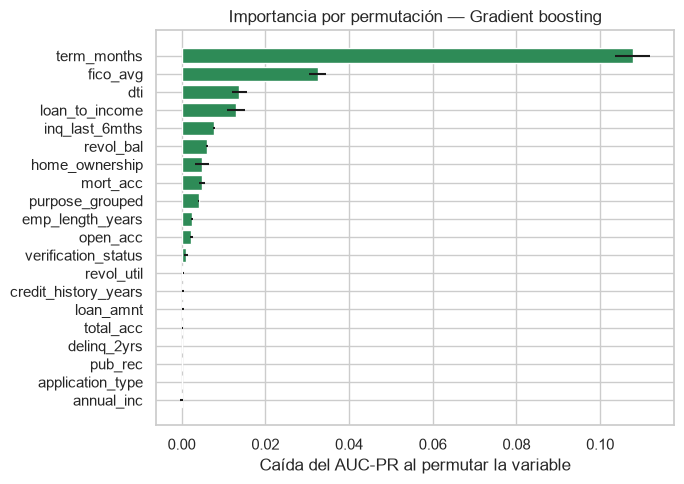

,variable,caida_pr_auc,desv
1,term_months,0.1078,0.0042
4,fico_avg,0.0325,0.0020
3,dti,0.0138,0.0017
15,loan_to_income,0.0130,0.0022
10,inq_last_6mths,0.0078,0.0003
7,revol_bal,0.0061,0.0002
17,home_ownership,0.0049,0.0017
12,mort_acc,0.0049,0.0007
16,purpose_grouped,0.0040,0.0002
13,emp_length_years,0.0024,0.0002


In [18]:
n_perm = 5_000 if QUICK else 30_000
sample = valid.sample(min(n_perm, len(valid)), random_state=SEED)
Xs, ys = models.get_xy(sample, grey)

perm = permutation_importance(model, Xs, ys, scoring="average_precision",
                              n_repeats=1 if QUICK else 3, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"variable": Xs.columns, "caida_pr_auc": perm.importances_mean, "desv": perm.importances_std}).sort_values("caida_pr_auc", ascending=False)
imp.to_csv(config.OUTPUTS / "permutation_importance_valid.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp["variable"][::-1], imp["caida_pr_auc"][::-1], xerr=imp["desv"][::-1], color="seagreen")
ax.set_xlabel("Caída del AUC-PR al permutar la variable")
ax.set_title(f"Importancia por permutación — {primary}")
plt.tight_layout(); savefig("04_importancia"); plt.show()
imp.round(4)


In [19]:
# Coeficientes (solo si el modelo principal es lineal)
clf = model.named_steps["clf"]
if hasattr(clf, "coef_"):
    nombres = model.named_steps["prep"].get_feature_names_out()
    coefs = pd.DataFrame({"variable": nombres, "coef": clf.coef_.ravel()})
    coefs["razon_de_odds"] = np.exp(coefs["coef"])
    coefs = coefs.sort_values("coef")
    top = pd.concat([coefs.head(10), coefs.tail(10)])
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.barh(top["variable"], top["coef"], color=np.where(top["coef"] > 0, "#C44E52", "#4C72B0"))
    ax.set_xlabel("Coeficiente (positivo = más riesgo de default)")
    ax.set_title("Regresión logística: 10 coeficientes más negativos y 10 más positivos")
    plt.tight_layout(); savefig("04_coeficientes"); plt.show()
    display(coefs.sort_values("coef", ascending=False).head(15).round(3))
else:
    print(f"El modelo principal ({primary}) no es lineal: no hay coeficientes. Ver importancia por permutación y dependencia parcial.")


El modelo principal (Gradient boosting) no es lineal: no hay coeficientes. Ver importancia por permutación y dependencia parcial.


**Dependencia parcial:** muestra cómo cambia el riesgo predicho (en promedio) al variar una variable numérica manteniendo el resto como está. Se grafican las tres numéricas más importantes.


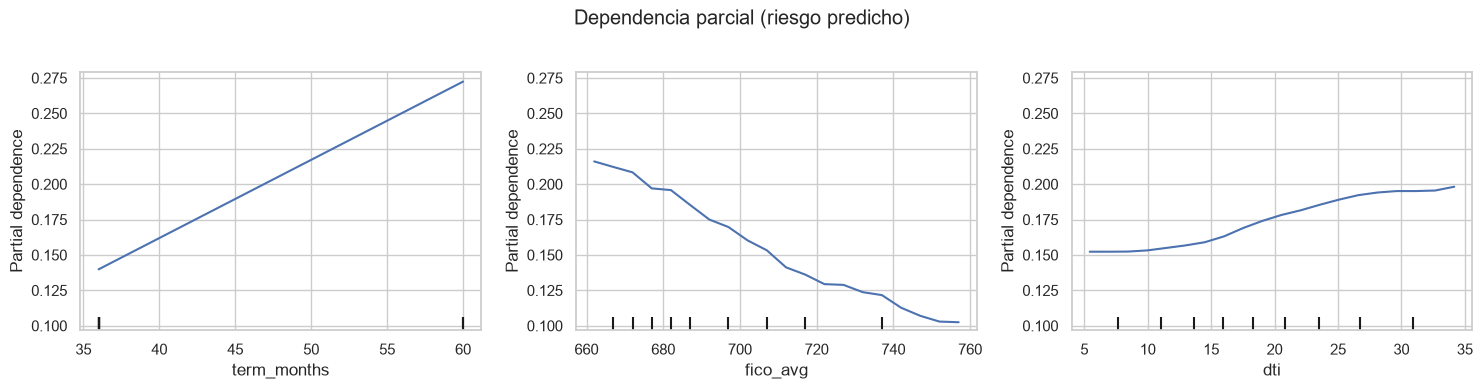

In [20]:
num_set = set(config.NUM_FEATURES + config.GREY_ZONE_NUM)
top_num = [v for v in imp["variable"] if v in num_set][:3]
fig, ax = plt.subplots(1, len(top_num), figsize=(5 * len(top_num), 3.8))
ax = np.atleast_1d(ax)
PartialDependenceDisplay.from_estimator(model, Xs.sample(min(10_000, len(Xs)), random_state=SEED), top_num,
                                        kind="average", grid_resolution=20, ax=ax)
plt.suptitle("Dependencia parcial (riesgo predicho)", y=1.02)
plt.tight_layout(); savefig("04_dependencia_parcial"); plt.show()


**Lectura:** (completar) ¿las variables más importantes y el sentido de su efecto tienen sentido económico (mejor FICO → menor riesgo, mayor DTI → mayor riesgo)?
Si alguna relación contradice el sentido común, revisar posible leakage o artefactos de los datos antes de confiar en el modelo.


## 7. Sesgos y equidad entre grupos

**Limitación previa:** el dataset **no contiene atributos protegidos** (sexo, raza, edad, etc.), así que no se puede auditar discriminación en sentido estricto.
Lo que sí se puede hacer es revisar **variables proxy** de situación socioeconómica o geográfica (estado, tenencia de vivienda, ingreso, antigüedad laboral, verificación de ingresos).

Marcar a alguien como "malo" equivale en la práctica a negarle o encarecerle el crédito, por lo que el indicador más sensible es la **tasa de falsos positivos** (`fpr`):
buenos pagadores marcados por error. También se compara el `recall` (igualdad de oportunidad) y la proporción de marcados contra el grupo de referencia (el más grande).
Que las tasas de marcados difieran no es en sí un sesgo si las tasas reales de default también difieren; por eso se mira junto con `fpr` y `recall`.


In [21]:
PROXIES = ["state_group", "home_ownership", "income_bin", "emp_bin", "verification_status"]
disp = evaluate.disparity_table(seg[seg["segmento"].isin(PROXIES)])
disp["alerta"] = np.where((disp["dif_fpr"].abs() > 0.05) | (~disp["ratio_marcados"].between(0.8, 1.25)), "revisar", "")
disp.to_csv(config.OUTPUTS / "fairness_proxies_valid.csv", index=False)
disp[["segmento", "valor", "referencia", "n", "tasa_default", "pct_marcados", "recall", "fpr",
      "ratio_marcados", "dif_recall", "dif_fpr", "alerta"]].round(3)


,segmento,valor,referencia,n,tasa_default,pct_marcados,recall,fpr,ratio_marcados,dif_recall,dif_fpr,alerta
0,emp_bin,<1 año,10+ años,30938,0.204,0.218,0.427,0.164,1.039,-0.010,0.009,
1,emp_bin,1-2 años,10+ años,58643,0.202,0.221,0.432,0.167,1.053,-0.005,0.011,
2,emp_bin,3-5 años,10+ años,74409,0.202,0.221,0.437,0.166,1.052,-0.000,0.010,
3,emp_bin,6-9 años,10+ años,65507,0.204,0.228,0.453,0.170,1.086,0.016,0.014,
4,emp_bin,10+ años,10+ años,123991,0.191,0.210,0.437,0.156,1.000,0.000,0.000,
5,emp_bin,desconocido,10+ años,22058,0.251,0.304,0.487,0.243,1.450,0.049,0.087,revisar
6,home_ownership,MORTGAGE,MORTGAGE,182130,0.175,0.187,0.402,0.141,1.000,0.000,0.000,
7,home_ownership,OWN,MORTGAGE,41072,0.206,0.223,0.418,0.173,1.194,0.017,0.031,
8,home_ownership,RENT,MORTGAGE,152342,0.233,0.266,0.484,0.200,1.423,0.082,0.059,revisar
9,income_bin,"1) 1,200–42,000","4) 74,000–100,000",77993,0.232,0.290,0.478,0.233,1.493,0.064,0.090,revisar


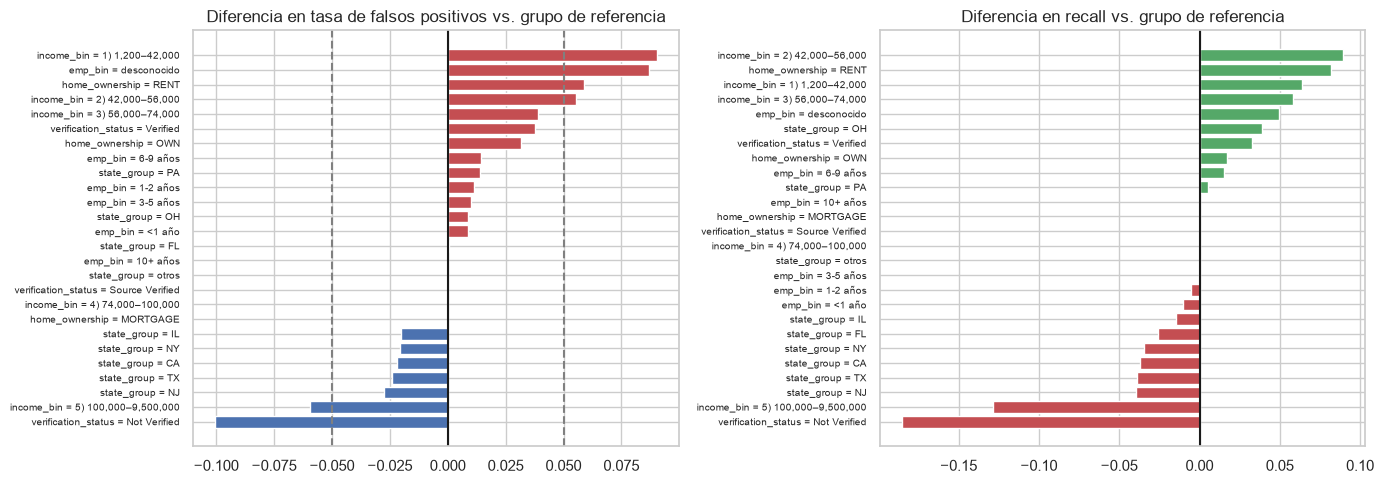

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
d = disp.assign(grupo=disp["segmento"] + " = " + disp["valor"]).sort_values("dif_fpr")
axes[0].barh(d["grupo"], d["dif_fpr"], color=np.where(d["dif_fpr"] > 0, "#C44E52", "#4C72B0"))
axes[0].axvline(0, color="k"); axes[0].axvline(0.05, color="gray", ls="--"); axes[0].axvline(-0.05, color="gray", ls="--")
axes[0].set_title("Diferencia en tasa de falsos positivos vs. grupo de referencia"); axes[0].tick_params(axis="y", labelsize=7)
d2 = disp.assign(grupo=disp["segmento"] + " = " + disp["valor"]).sort_values("dif_recall")
axes[1].barh(d2["grupo"], d2["dif_recall"], color=np.where(d2["dif_recall"] > 0, "#55A868", "#C44E52"))
axes[1].axvline(0, color="k")
axes[1].set_title("Diferencia en recall vs. grupo de referencia"); axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); savefig("04_equidad"); plt.show()


**Lectura:** (completar) ¿qué grupos quedan marcados como «revisar»? Interpretar con cuidado:
- Un `fpr` más alto en un grupo significa que sus buenos pagadores son rechazados con más frecuencia que en el grupo de referencia.
- Parte de la diferencia puede ser real (distinto perfil de riesgo) y parte artefacto del modelo; con estos datos no se puede separar del todo.
- **Sesgo de selección:** el dataset solo contiene préstamos que Lending Club ya aprobó (no hay rechazados), así que el modelo hereda esa selección y no sabemos cómo se comportaría con solicitantes que antes se rechazaban.
- **Deriva temporal:** el modelo se entrena con 2012–2014 y puede comportarse distinto en poblaciones que cambian con el tiempo.


## 8. Guardar resultados

In [23]:
print("Archivos generados en outputs/:")
for f in ["error_analysis_segments_valid.csv", "permutation_importance_valid.csv", "fairness_proxies_valid.csv"]:
    print(" -", f, "OK" if (config.OUTPUTS / f).exists() else "NO ENCONTRADO")
print("Figuras en reports/figures/: 04_*.png")


Archivos generados en outputs/:
 - error_analysis_segments_valid.csv OK
 - permutation_importance_valid.csv OK
 - fairness_proxies_valid.csv OK
Figuras en reports/figures/: 04_*.png


## 9. (Opcional) Comportamiento en test — SOLO después de la evaluación final

> **Cuidado:** esta sección describe cómo se comportó el modelo ya evaluado en test. **No debe usarse para cambiar el modelo, el umbral ni las variables**:
> hacerlo convertiría al test en un conjunto de decisión y anularía su validez. Se activa con `ANALYZE_TEST = True` en la primera celda, y requiere haber ejecutado antes
> `python -m src.train --stage final`, que guarda las predicciones en `data/processed/artifacts/predictions_test.parquet`.


In [24]:
pred_test = config.DATA_PROCESSED / "artifacts" / "predictions_test.parquet"
if not ANALYZE_TEST:
    print("ANALYZE_TEST = False: sección omitida (el test no se toca en este análisis).")
elif not pred_test.exists():
    print("No existe", pred_test, "\nEjecuta primero la etapa final: python -m src.train --stage final")
else:
    test = pd.read_parquet(pred_test)
    test = evaluate.add_analysis_segments(test)
    y_te = test["target"].values
    print(f"Test: {len(test):,} préstamos | tasa de default: {y_te.mean():.3f} (valid: {y_va.mean():.3f})")

    comp_global = pd.concat([
        pd.Series(evaluate.evaluate_scores(y_va, valid["score"].values, MIN_PRECISION), name="validación"),
        pd.Series(evaluate.evaluate_scores(y_te, test["score"].values, MIN_PRECISION), name="test"),
    ], axis=1)
    display(comp_global.round(4))

    seg_te = pd.concat([evaluate.segment_metrics(test, c, thr, min_rows=MIN_ROWS_SEGMENT) for c in ["fico_bin", "term_months", "purpose", "state_group"]])
    seg_te.to_csv(config.OUTPUTS / "error_analysis_segments_test.csv", index=False)
    seg_va = seg[seg["segmento"].isin(["fico_bin", "term_months", "purpose", "state_group"])]
    cmp_seg = seg_va.merge(seg_te, on=["segmento", "valor"], suffixes=("_valid", "_test"))
    cmp_seg["dif_roc_auc"] = cmp_seg["roc_auc_test"] - cmp_seg["roc_auc_valid"]
    display(cmp_seg[["segmento", "valor", "n_valid", "n_test", "roc_auc_valid", "roc_auc_test", "dif_roc_auc", "recall_valid", "recall_test"]].round(3))


ANALYZE_TEST = False: sección omitida (el test no se toca en este análisis).


## 10. Conclusiones (completar con los resultados reales)

- **Dónde falla el modelo:** segmentos con peor ROC-AUC/recall y tamaño de esos grupos.
- **Tipo de error dominante:** falsos negativos vs. falsos positivos y qué costo implica cada uno.
- **Qué variables importan:** coincidencia entre importancia por permutación, coeficientes y sentido económico.
- **Sesgos y equidad:** grupos marcados como «revisar», limitaciones (sin atributos protegidos, sesgo de selección, deriva temporal).
- **Mejoras posibles (trabajo futuro):** variables nuevas (p. ej. `emp_title` procesado), umbrales por segmento (con cuidado ético), recalibración, más años de entrenamiento.
- **Siguiente paso:** informe final (`reports/informe_final.md`) y presentación.
